This notebook runs an LMDI analysis on electricity sector emissions

In [2]:
import os, sys
sys.path.append('../scripts')

from peak_tester import EmissionsPeakTest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_indexing as pix
from pandas_indexing import *

import joblib

from helper_functions import HiddenPrints, segment_by_peaks, combine_countries

In [3]:
ember = pd.read_csv('../data/processed/ember_electricity.csv', index_col=[0,1,2,3])
ember.columns = ember.columns.astype(int)
all_countries = ember.index.get_level_values('region').unique()

In [47]:
all_countries

Index(['ABW', 'AFG', 'AGO', 'ARE', 'ARG', 'ARM', 'ASM', 'ATG', 'AUS', 'AUT',
       ...
       'WSM', 'XKX', 'YEM', 'ZAF', 'ZMB', 'ZWE', 'WLD', 'EU27', 'G20',
       'G20_excl_CHN'],
      dtype='object', name='region', length=215)

In [17]:
# Add country groups

# combine_countries(all_countries, 'ember_electricity.csv', countries_name = 'WLD')

EU27 = [
    'AUT', 'BEL', 'BGR', 'HRV', 'CYP', 'CZE', 'DNK', 'EST', 'FIN', 'FRA',
    'DEU', 'GRC', 'HUN', 'IRL', 'ITA', 'LVA', 'LTU', 'LUX', 'MLT', 'NLD',
    'POL', 'PRT', 'ROU', 'SVK', 'SVN', 'ESP', 'SWE'
]
# Add EU27
# combine_countries(EU27, 'ember_electricity.csv', countries_name = 'EU27')

G20_ISOS = ['AUS','ARG','BRA','CAN','CHN','EU27','IND','IDN','JPN','MEX','RUS','SAU','KOR','TUR','GBR','USA','ZAF'] 

# Add G20
# combine_countries(G20_ISOS, 'ember_electricity.csv', countries_name='G20')

# Add G20_excl_CHN 
G20_excl_CHN = [item for item in G20_ISOS if item != 'CHN']
# combine_countries(G20_excl_CHN, 'ember_electricity.csv', countries_name='G20_excl_CHN')

In [5]:
def perform_power_lmdi(
    region,
    data_df,
    year_range=range(2000, 2026),
    aggregate_fuels=True
):
    """
    Additive LMDI decomposition of power sector CO2 emissions.

    Equation: CO2 = Q * sum_i(Q_i/Q * CO2_i/Q_i)
    Decomposes annual change into:
        - Scale effect:     change in total generation Q
        - Structure effect: change in fuel mix Q_i/Q
        - Intensity effect: change in emissions intensity CO2_i/Q_i

    Args:
        region:         ISO code or list of ISO codes to aggregate
        data_df:       formatted DataFrame with electricity data (multi-index: region,
                        region_name, variable, unit; years as integers)
        year_range:     years to include
        aggregate_fuels: if True, aggregate fuels into broad categories
                        after decomposition

    Returns:
        DataFrame with columns: year, scale_effect, structure_effect,
        intensity_effect, total_change, computed_change, and per-fuel
        structure and intensity contributions
    """
    years = sorted([y for y in year_range
                    if y in data_df.columns])

    fuels = [
        'Bioenergy', 'Coal', 'Gas', 'Hydro', 'Nuclear',
        'Other Fossil', 'Other Renewables', 'Solar', 'Wind'
    ]

    fuel_groups = {
        'Coal':        ['Coal'],
        'Gas':         ['Gas'],
        'Other Fossil':['Other Fossil'],
        'Nuclear':     ['Nuclear'],
        'Renewables':  ['Bioenergy', 'Hydro', 'Other Renewables', 'Solar', 'Wind'],
    }

    def get_series(variable, unit, regions, years):
        """Extract a time series for one variable, summing across regions."""
        if isinstance(regions, str):
            regions = [regions]
        rows = data_df[
            (data_df.index.get_level_values('region').isin(regions)) &
            (data_df.index.get_level_values('variable') == variable) &
            (data_df.index.get_level_values('unit') == unit)
        ]
        if rows.empty:
            return pd.Series(0.0, index=years)
        return rows[years].sum()

    regions = [region] if isinstance(region, str) else region

    # Load total generation and total emissions
    Q_total = get_series('Electricity_generation|Total', 'TWh', regions, years)
    E_total = get_series('Emissions|CO2|Power Industry|Total', 'MtCO2', regions, years)

    # Load per-fuel generation and emissions
    Q_fuel = {}
    E_fuel = {}
    for fuel in fuels:
        Q_fuel[fuel] = get_series(f'Electricity_generation|{fuel}', 'TWh', regions, years)
        E_fuel[fuel] = get_series(f'Emissions|CO2|Power Industry|{fuel}', 'MtCO2', regions, years)

    def log_mean(x, y):
        if abs(x - y) < 1e-10:
            return (x + y) / 2
        if x <= 0 or y <= 0:
            return 0.0
        return (x - y) / (np.log(x) - np.log(y))

    records = []

    for t in range(len(years) - 1):
        yr0, yr1 = years[t], years[t + 1]
        Q0, Q1 = Q_total[yr0], Q_total[yr1]
        E0, E1 = E_total[yr0], E_total[yr1]

        if Q0 <= 0 or Q1 <= 0 or E0 <= 0 or E1 <= 0:
            continue

        L_total = log_mean(E1, E0)
        total_change = E1 - E0

        scale_effect     = 0.0
        structure_effect = 0.0
        intensity_effect = 0.0

        fuel_structure = {}
        fuel_intensity = {}
        fuel_scale ={}

        for fuel in fuels:
            qi0 = Q_fuel[fuel][yr0]
            qi1 = Q_fuel[fuel][yr1]
            ei0 = E_fuel[fuel][yr0]
            ei1 = E_fuel[fuel][yr1]

            if qi0 <= 0 or qi1 <= 0:
                fuel_structure[fuel] = 0.0
                fuel_intensity[fuel] = 0.0
                fuel_scale[fuel] = 0.0
                continue

            # Fuel-level emissions: ei = Q * (qi/Q) * (ei/qi)
            # Weights for LMDI
            L_fuel = log_mean(
                Q1 * (qi1/Q1) * (ei1/qi1) if qi1 > 0 else 1e-10,
                Q0 * (qi0/Q0) * (ei0/qi0) if qi0 > 0 else 1e-10,
            )

            # Scale: ln(Q1/Q0)
            if Q1 > 0 and Q0 > 0:
                scale = L_fuel * np.log(Q1 / Q0)
            else:
                scale = 0
            scale_effect += scale
            fuel_scale[fuel] = scale

            # Structure: ln((qi1/Q1) / (qi0/Q0))
            s0, s1 = qi0 / Q0, qi1 / Q1
            if s0 > 0 and s1 > 0:
                struct = L_fuel * np.log(s1 / s0)
            else:
                struct = 0.0
            structure_effect     += struct
            fuel_structure[fuel]  = struct

            # Intensity: ln((ei1/qi1) / (ei0/qi0))
            i0, i1 = ei0 / qi0, ei1 / qi1
            if i0 > 0 and i1 > 0:
                intens = L_fuel * np.log(i1 / i0)
            else:
                intens = 0.0
            intensity_effect     += intens
            fuel_intensity[fuel]  = intens

        record = {
            'year':             int(yr1),
            'emissions':        E1,
            'total_change':     total_change,
            'computed_change':  scale_effect + structure_effect + intensity_effect,
            'scale_effect':     scale_effect,
            'structure_effect': structure_effect,
            'intensity_effect': intensity_effect,
        }

        # Add per-fuel contributions
        for fuel in fuels:
            record[f'structure_{fuel}'] = fuel_structure.get(fuel, 0.0)
            record[f'intensity_{fuel}'] = fuel_intensity.get(fuel, 0.0)
            record[f'scale_{fuel}'] = fuel_scale.get(fuel, 0.0)
            record[f'generation_mix_{fuel}'] = fuel_structure.get(fuel, 0.0) + fuel_scale.get(fuel, 0.0)

        records.append(record)

    result = pd.DataFrame(records)

    # Optionally aggregate fuels into broad groups
    if aggregate_fuels:
        for group, members in fuel_groups.items():
            result[f'structure_{group}'] = result[[f'structure_{f}' for f in members]].sum(axis=1)
            result[f'intensity_{group}'] = result[[f'intensity_{f}' for f in members]].sum(axis=1)
            result[f'scale_{group}'] = result[[f'scale_{f}' for f in members]].sum(axis=1)
            # Only drop if the group name differs from the member names
            # (i.e. multiple members were merged under a new group name)
            cols_to_drop = [
                f'structure_{f}' for f in members if f != group
            ] + [
                f'intensity_{f}' for f in members if f != group
            ] + [
                f'scale_{f}' for f in members if f != group
            ]
            if cols_to_drop:
                result = result.drop(columns=cols_to_drop)

    return result

In [37]:
# Check all variables available for CHN
chn_vars = ember[ember.index.get_level_values('region') == 'CHN'].index.get_level_values('variable').unique()
print(sorted(chn_vars))

['Electricity_generation|Bioenergy', 'Electricity_generation|Coal', 'Electricity_generation|Gas', 'Electricity_generation|Hydro', 'Electricity_generation|Nuclear', 'Electricity_generation|Other Fossil', 'Electricity_generation|Solar', 'Electricity_generation|Total', 'Electricity_generation|Wind', 'Emissions|CO2|Power Industry|Bioenergy', 'Emissions|CO2|Power Industry|Coal', 'Emissions|CO2|Power Industry|Gas', 'Emissions|CO2|Power Industry|Hydro', 'Emissions|CO2|Power Industry|Nuclear', 'Emissions|CO2|Power Industry|Other Fossil', 'Emissions|CO2|Power Industry|Solar', 'Emissions|CO2|Power Industry|Total', 'Emissions|CO2|Power Industry|Wind']


In [18]:
# Single country
power_lmdi = {}
for iso in G20_ISOS:
    try:
        power_lmdi[iso] = perform_power_lmdi(iso, ember)
    except Exception as e:
        print(f"{iso}: {e}")

# # Country group — pass a list of ISOs
# power_lmdi['EU27'] = perform_power_lmdi(EU27, ember)
# power_lmdi['G20']  = perform_power_lmdi(
#     [iso for iso in G20_ISOS if iso in ember.index.get_level_values('region')],
#     ember
# )

In [19]:
# ember.loc[('IND', slice(None), slice(None), slice(None)), 2000:]
# edgar.loc[('WLD', slice(None), 'Emissions|GHG|Total_incl_LULUCF', slice(None)), 1990:]
pd.set_option('display.max_columns', None)
power_lmdi['GBR']

,year,emissions,total_change,computed_change,scale_effect,structure_effect,intensity_effect,generation_mix_Bioenergy,structure_Coal,intensity_Coal,scale_Coal,generation_mix_Coal,structure_Gas,intensity_Gas,scale_Gas,generation_mix_Gas,generation_mix_Hydro,structure_Nuclear,intensity_Nuclear,scale_Nuclear,generation_mix_Nuclear,structure_Other Fossil,intensity_Other Fossil,scale_Other Fossil,generation_mix_Other Fossil,generation_mix_Other Renewables,generation_mix_Solar,generation_mix_Wind,structure_Renewables,intensity_Renewables,scale_Renewables
0,2001,203.54,6.72,6.72,4.049511,2.677627,-0.007138,0.140669,8.610651,-0.002185,2.441534,11.052185,-4.365897,-0.001277,1.407174,-2.958723,-0.025072,0.015626,-0.004125,0.008500,0.024125,-1.677753,-0.003744,0.171497,-1.506256,0.0,0.000000,0.000211,0.095001,0.004193,0.020806
1,2002,201.71,-1.83,-1.83,1.296172,-3.127462,0.001289,0.119041,-7.679640,-0.005811,0.785450,-6.894189,4.521465,-0.002625,0.451160,4.972625,0.017607,-0.013420,0.000700,0.002719,-0.010700,-0.088912,0.009480,0.049431,-0.039480,0.0,0.000000,0.003808,0.133045,-0.000456,0.007411
2,2003,213.75,12.04,12.04,5.799268,6.243561,-0.002829,0.235474,10.094806,-0.004947,3.520141,13.614947,-3.647293,0.000343,2.016950,-1.630343,-0.037121,-0.007828,0.005956,0.011872,0.004044,-0.358077,-0.005199,0.213276,-0.144801,0.0,0.000000,0.000630,0.161953,0.001018,0.037030
3,2004,211.15,-2.60,-2.60,-2.300640,-0.288278,-0.011083,0.256805,-4.998978,-0.006062,-1.404960,-6.403938,4.716988,0.007379,-0.794366,3.922621,0.038100,-0.037808,0.002246,-0.004437,-0.042246,-0.288554,-0.001580,-0.079867,-0.368420,0.0,0.000000,0.008161,0.320075,-0.013066,-0.017009
4,2005,213.22,2.07,2.07,2.372568,-0.312236,0.009668,0.376303,1.305967,-0.006184,1.430218,2.736184,-2.950065,-0.000341,0.830406,-2.119659,0.001884,0.003457,-0.007819,0.004361,0.007819,0.960057,0.003798,0.086145,1.046202,0.0,0.000000,0.011600,0.368349,0.020213,0.021438
5,2006,222.21,8.99,8.99,-0.590626,9.588570,-0.007944,0.038977,14.011713,0.007430,-0.369143,13.642570,-5.472408,-0.006664,-0.190928,-5.663336,-0.007979,-0.028443,-0.000539,-0.001018,-0.029461,1.024064,-0.000362,-0.023702,1.000362,0.0,0.000000,0.016811,0.053645,-0.007809,-0.005836
6,2007,220.65,-1.56,-1.56,-0.256231,-1.294239,-0.009530,0.008645,-12.236292,-0.005428,-0.158280,-12.394572,12.053763,0.001221,-0.084984,11.968779,0.011657,-0.058808,-0.000810,-0.000381,-0.059190,-1.088943,-0.001002,-0.010055,-1.098998,0.0,0.000000,0.013207,0.036041,-0.003510,-0.002531
7,2008,215.63,-5.02,-5.02,-4.356286,-0.667156,0.003442,0.071321,-8.602975,-0.001834,-2.495191,-11.098166,6.639315,-0.001375,-1.637940,5.001375,0.001409,-0.044703,0.000183,-0.005480,-0.050183,1.199477,0.003255,-0.172732,1.026745,0.0,0.000000,0.024056,0.141730,0.003214,-0.044944
8,2009,190.13,-25.50,-25.50,-6.454178,-19.046616,0.000794,0.229597,-17.018374,-0.002979,-3.468647,-20.487021,-2.043002,0.000904,-2.617902,-4.660904,0.002083,0.088405,0.000778,-0.009183,0.079222,-0.410162,0.001255,-0.281093,-0.691255,0.0,0.000000,0.027483,0.336516,0.000837,-0.077353
9,2010,197.60,7.47,7.47,2.707223,4.757574,0.005203,0.335388,2.955967,0.001888,1.412145,4.368112,3.241970,0.002333,1.145697,4.387667,-0.039237,-0.037814,0.003417,0.004397,-0.033417,-1.673743,-0.003377,0.107120,-1.566623,0.0,0.000000,0.012907,0.271194,0.000942,0.037865


In [77]:
def plot_power_lmdi_country(country, power_lmdi, peak_results, ember_df, figsize=(12, 10)):
    data = power_lmdi[country]
    years = np.array(data['year'])

    fossil_groups = {
        'Coal':         '#4C4C4C',
        'Gas':          "#7E38E8",
        'Other Fossil': "#3035C8",
    }


    # ── Renewables + nuclear share from ember_df ──────────────────────────────
    low_co2_fuels = ['Bioenergy', 'Hydro', 'Nuclear', 'Other Renewables', 'Solar', 'Wind']

    def get_generation(variable, region):
        rows = ember_df[
            (ember_df.index.get_level_values('region') == region) &
            (ember_df.index.get_level_values('variable') == variable)
        ]
        if rows.empty:
            return pd.Series(0.0, index=years)
        int_cols = [c for c in rows.columns if isinstance(c, int) and c in years]
        return rows[int_cols].sum().reindex(years)

    total_gen   = get_generation('Electricity_generation|Total', country)
    low_co2_gen = sum(
        get_generation(f'Electricity_generation|{f}', country)
        for f in low_co2_fuels
    )
    low_co2_share = (low_co2_gen / total_gen * 100)

    # ── Figure layout ─────────────────────────────────────────────────────────
    fig, (ax_share, ax_em, ax_lmdi) = plt.subplots(
        3, 1, figsize=figsize, sharex=True,
        gridspec_kw={'height_ratios': [0.6, 0.6, 0.9]}
    )

    # ── Top panel: low-carbon share and total generation ───────────────────────────────────────────
    ax_share.fill_between(years, low_co2_share.values, alpha=0.3, color='#1D9E75')
    ax_share.plot(years, low_co2_share.values, color='#1D9E75', linewidth=1.5)
    ax_share.set_ylabel('Low-carbon\nshare (%)', fontsize=9)
    ax_share.set_ylim(0, 100)
    ax_share.spines[['top', 'right']].set_visible(False)
    ax_share.grid(axis='y', alpha=0.3, linewidth=0.5)
    ax_share.set_title(country, fontsize=12, fontweight='bold')

        # Add total generation to first panel
    ax_share2 = ax_share.twinx()
    total_gen.plot(ax = ax_share2, color = 'orange')
    ax_share2.set_ylabel('Total generation (TWh)', fontsize=9)

    # ── Middle panel: emissions ───────────────────────────────────────────────
    emissions = np.array(data['emissions'])
    ax_em.plot(years, emissions, color='royalblue', linewidth=1.8)
    ax_em.fill_between(years, emissions, alpha=0.15, color='royalblue')
    ax_em.set_ylabel('Emissions (MtCO₂)', fontsize=9)
    ax_em.set_ylim(emissions.min() * 0.95, emissions.max() * 1.05)
    ax_em.spines[['top', 'right']].set_visible(False)
    ax_em.grid(axis='y', alpha=0.3, linewidth=0.5)
    ax_em.set_xlim(2000, 2026)

        # Peak probabilities on twin axis of middle panel
    ax_em2 = ax_em.twinx()
    if 'sequential' in peak_results and country in peak_results['sequential']:
        peak_results['sequential'][country].plot(
            ax=ax_em2, color='purple', linestyle='--',
            linewidth=1.2, label='Sequential'
        )
    if 'slope' in peak_results and country in peak_results['slope']:
        peak_results['slope'][country].plot(
            ax=ax_em2, color='black', linestyle='-',
            linewidth=1.2, label='Slope'
        )
    ax_em2.set_ylim(0, 1.01)
    ax_em2.axhline(0.66, color='grey', linewidth=0.5, linestyle=':', alpha=0.7)
    ax_em2.set_ylabel('Peak probability', fontsize=9)
    ax_em2.legend(loc='upper right', fontsize=7, framealpha=0.5)

    # ── Bottom panel: scale + structure stacked by fuel + intensity ───────────
    pos_bottom = np.zeros(len(years))
    neg_bottom = np.zeros(len(years))

    effects = [
            ('structure', None, 0.4,  ' (structure)'),
            ('scale',     None, 0.85, ' (scale)')
        ]

    # Swap the loop hierarchy: effects on the outside, fossil groups on the inside
    for effect, hatch, alpha, suffix in effects:
        for label, color in fossil_groups.items():
            col = f'{effect}_{label}'
            if col not in data.columns:
                continue
            vals = np.array(data[col])
            pos_vals = np.where(vals > 0, vals, 0)
            neg_vals = np.where(vals < 0, vals, 0)

            ax_lmdi.bar(years, pos_vals, bottom=pos_bottom,
                    color=color, alpha=alpha, width=0.8,
                    hatch=hatch, edgecolor='white' if hatch else color,
                    linewidth=0.3,
                    label=f'{label}{suffix}')
            ax_lmdi.bar(years, neg_vals, bottom=neg_bottom,
                    color=color, alpha=alpha, width=0.8,
                    hatch=hatch, edgecolor='white' if hatch else color,
                    linewidth=0.3)
            pos_bottom += pos_vals
            neg_bottom += neg_vals

    # Total intensity as final stacked segment
    total_intensity = np.array(data['intensity_effect'])
    pos_int = np.where(total_intensity > 0, total_intensity, 0)
    neg_int = np.where(total_intensity < 0, total_intensity, 0)
    ax_lmdi.bar(years, pos_int, bottom=pos_bottom,
               color="#4AC3AB", alpha=0.85, width=0.8, label='Total intensity')
    ax_lmdi.bar(years, neg_int, bottom=neg_bottom,
               color="#4AC3AB", alpha=0.85, width=0.8)

    # Net change line
    ax_lmdi.hlines(data['total_change'], years - 0.35, years + 0.35,
                  colors='black', linewidth=1.0, zorder=5)
    ax_lmdi.axhline(0, color='black', linewidth=0.5, alpha=0.4)
    ax_lmdi.set_ylabel('LMDI contribution (MtCO₂)', fontsize=9)
    ax_lmdi.spines[['top', 'right']].set_visible(False)
    ax_lmdi.grid(axis='y', alpha=0.3, linewidth=0.5)
    ax_lmdi.legend(loc='lower left', fontsize=7, ncol=2, framealpha=0.5)



    plt.tight_layout()
    return fig

In [52]:
co2_power = {}
co2_power['slope'] = pd.read_csv("../outputs/data/edgar_analysis/co2_power_growing_window_slope.csv", index_col= 0)
co2_power['sequential'] = pd.read_csv("../outputs/data/edgar_analysis/co2_power_growing_window_sequential.csv", index_col = 0)

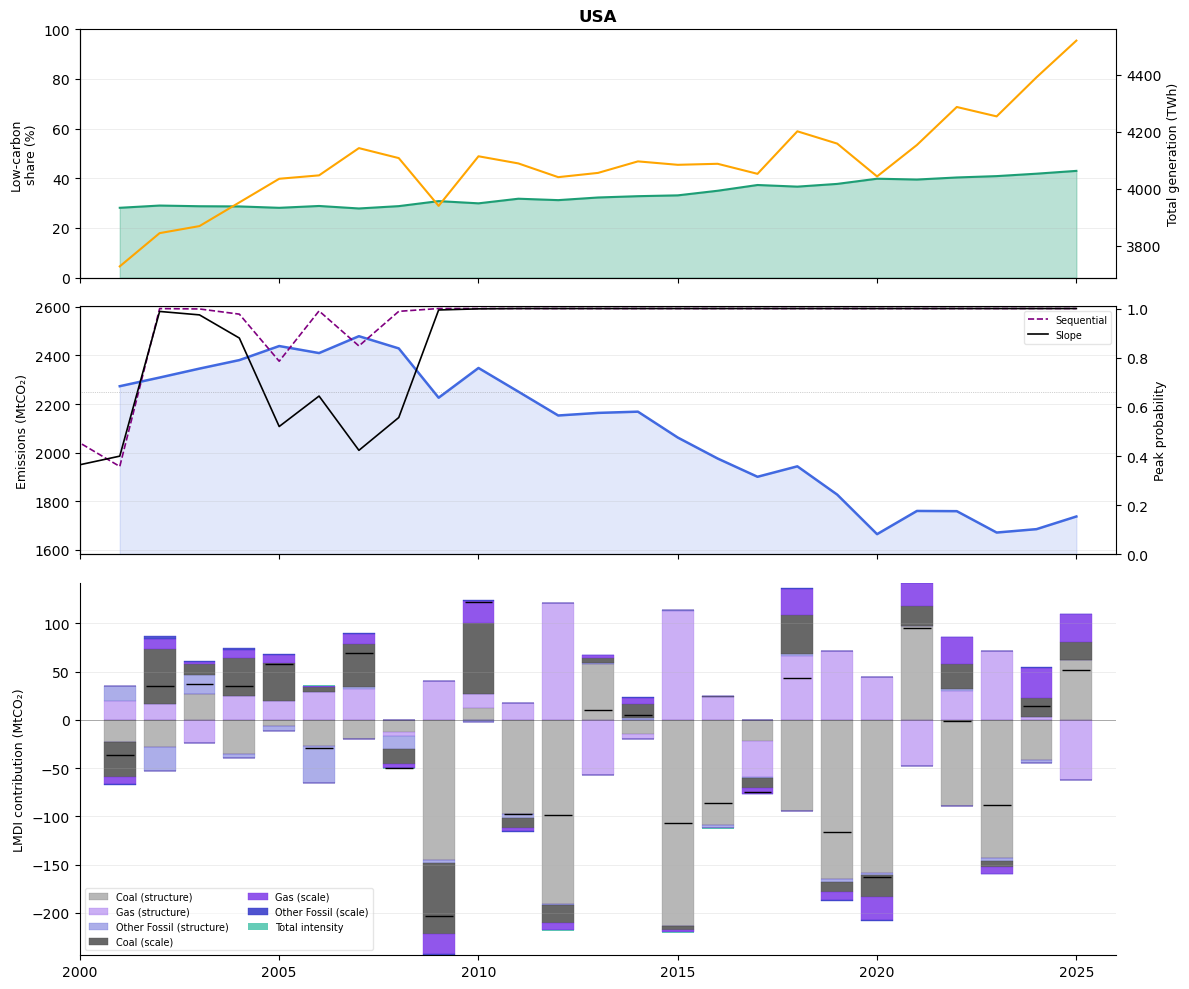

In [81]:
for country in ['USA']:
    if country not in power_lmdi:
        continue
    fig = plot_power_lmdi_country(
        country, power_lmdi, co2_power, ember
    )
    plt.show()

In [13]:
# Plot


def plot_power_lmdi(lmdi_df, country_name="Region", save_fig=False):
    """Plots 3 stacked panels (Scale, Structure, Intensity) with shared Y-axes."""
    # Exclude non-fuel summary columns
    fuel_cols = [
        col.replace("scale_", "")
        for col in lmdi_df.columns
        if col.startswith("scale_") and col != "scale_effect"
    ]

    color_map = {
        "Coal": "#333333",
        "Gas": "#E66101",
        "Other Fossil": "#999999",
        "Nuclear": "#5E3C99",
        "Renewables": "#2CA02C",
        "Bioenergy": "#8C564B",
        "Hydro": "#1F77B4",
        "Solar": "#FF7F0E",
        "Wind": "#17BECF",
        "Other Renewables": "#BCBD22",
    }

    default_colors = plt.cm.tab10.colors
    years = lmdi_df["year"].values

    panels = [
        ("scale", "Scale Effect (Total Generation $Q$)"),
        ("structure", "Structure Effect (Fuel Mix $Q_i/Q$)"),
        ("intensity", "Efficiency / Intensity Effect ($CO_2,i/Q_i$)"),
    ]

    # First pass: Determine global y-limits across ALL panels for consistent scaling
    global_min = 0.0
    global_max = 0.0

    for effect_prefix, _ in panels:
        pos_bottom = np.zeros(len(lmdi_df))
        neg_bottom = np.zeros(len(lmdi_df))

        for fuel in fuel_cols:
            col_name = f"{effect_prefix}_{fuel}"
            if col_name in lmdi_df.columns:
                vals = lmdi_df[col_name].values
                pos_bottom += np.where(vals >= 0, vals, 0)
                neg_bottom += np.where(vals < 0, vals, 0)

        net_col = f"{effect_prefix}_effect"
        net_vals = (
            lmdi_df[net_col].values if net_col in lmdi_df.columns else np.array([])
        )

        current_min = min(neg_bottom.min(), net_vals.min() if len(net_vals) else 0)
        current_max = max(pos_bottom.max(), net_vals.max() if len(net_vals) else 0)

        global_min = min(global_min, current_min)
        global_max = max(global_max, current_max)

    # Add 8% padding to top/bottom for clean visuals
    pad = (global_max - global_min) * 0.08
    y_lims = (global_min - pad, global_max + pad)

    # Second pass: Plot subplots
    fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True, dpi=120)

    for ax, (effect_prefix, title) in zip(axes, panels):
        pos_bottom = np.zeros(len(lmdi_df))
        neg_bottom = np.zeros(len(lmdi_df))

        for idx, fuel in enumerate(fuel_cols):
            col_name = f"{effect_prefix}_{fuel}"
            if col_name not in lmdi_df.columns:
                continue

            vals = lmdi_df[col_name].values
            color = color_map.get(fuel, default_colors[idx % 10])
            bottoms = np.where(vals >= 0, pos_bottom, neg_bottom)

            ax.bar(
                years,
                vals,
                bottom=bottoms,
                label=fuel,
                color=color,
                edgecolor="white",
                linewidth=0.4,
                width=0.8,
            )

            pos_bottom += np.where(vals >= 0, vals, 0)
            neg_bottom += np.where(vals < 0, vals, 0)

        # Plot net line
        net_col = f"{effect_prefix}_effect"
        if net_col in lmdi_df.columns:
            ax.plot(
                years,
                lmdi_df[net_col],
                color="black",
                linestyle="--",
                marker="o",
                markersize=4,
                linewidth=1.2,
                label="Net Effect",
            )

        # Apply standardized Y-limits across all subplots
        ax.set_ylim(y_lims)
        ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
        ax.set_title(title, fontsize=12, fontweight="bold", pad=8)
        ax.set_ylabel(r"$\Delta$ $\mathrm{CO_2}$ (Mt$\mathrm{CO_2}$)")
        ax.grid(axis="y", linestyle=":", alpha=0.6)

    axes[-1].set_xlabel("Year", fontsize=11)
    axes[-1].set_xticks(years)
    axes[-1].set_xticklabels(years, rotation=45)

    fig.suptitle(
        f"LMDI Decomposition of Power Sector CO₂ Emissions: {country_name}",
        fontsize=14,
        fontweight="bold",
        y=0.98,
    )

    # Consolidated Legend
    handles, labels = axes[0].get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    fig.legend(
        by_label.values(),
        by_label.keys(),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.94),
        ncol=min(len(by_label), 6),
        frameon=True,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.92])

    if save_fig:
        plt.savefig(
            f"lmdi_decomposition_{country_name}.png",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()

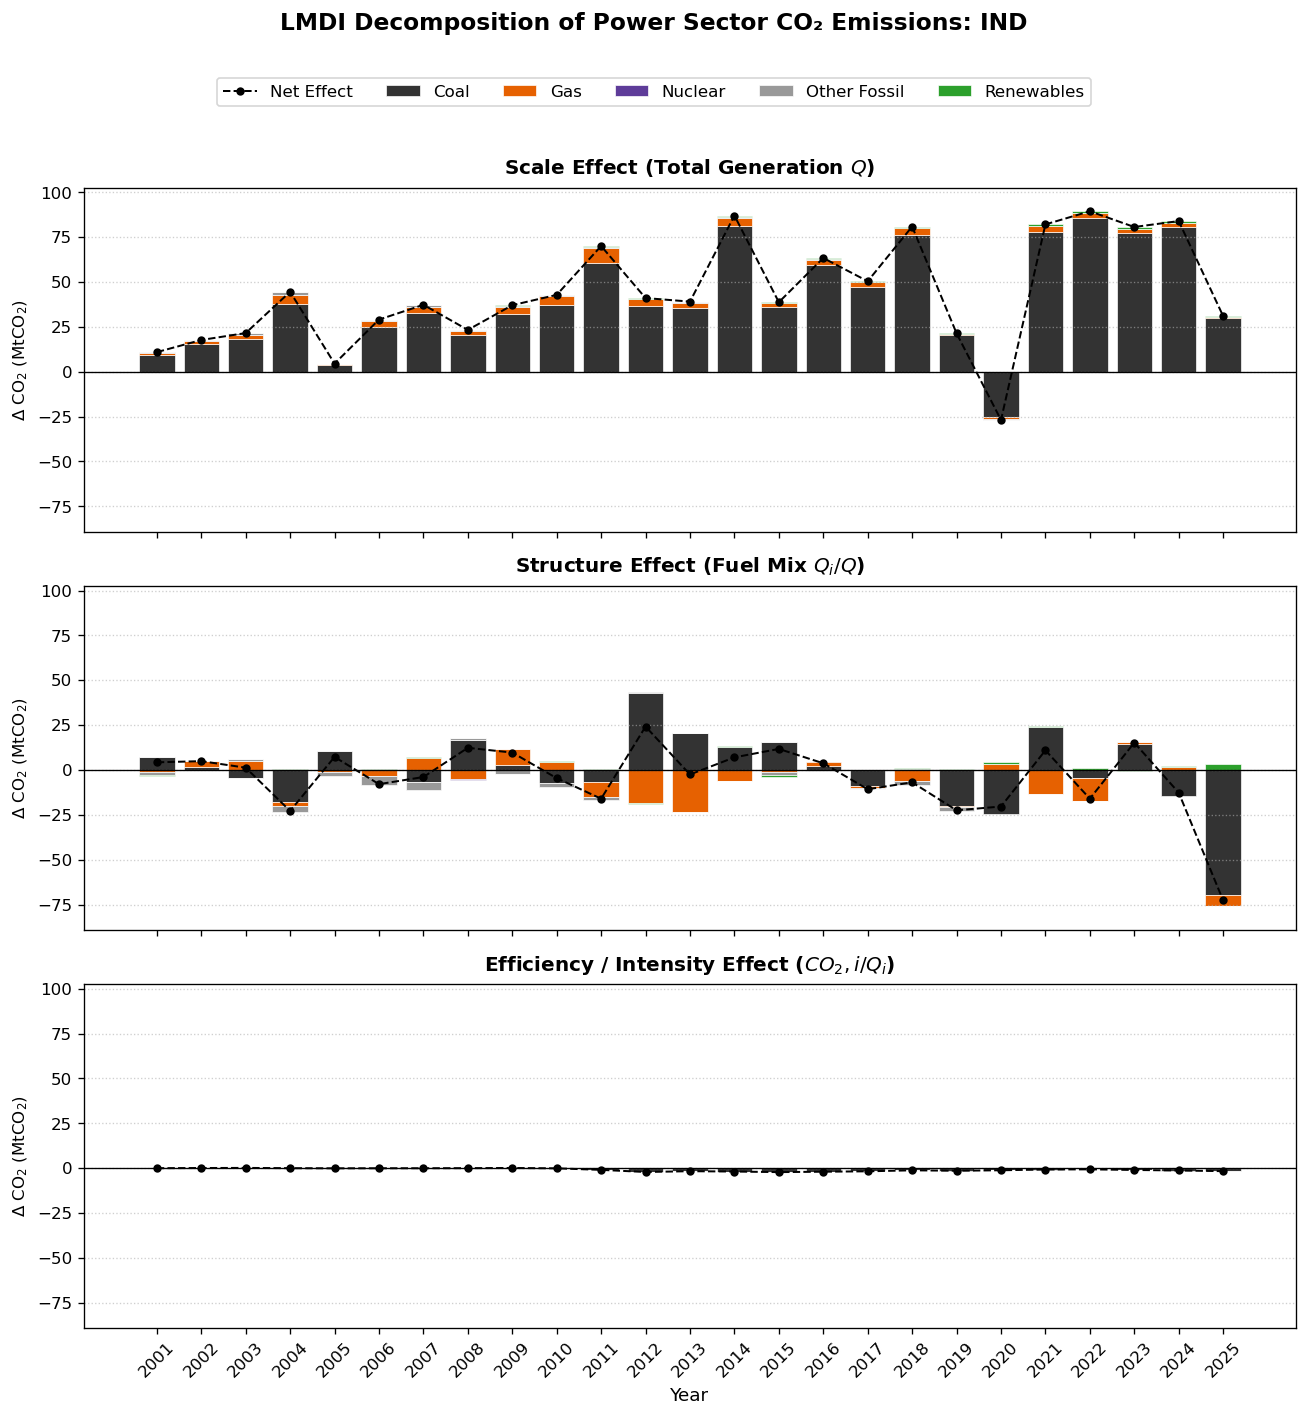

In [14]:
# Plot the 3 panels
plot_power_lmdi(power_lmdi['IND'], country_name="IND")

In [ ]:
# old below - delete

In [ ]:
em_data = dict()
ci_data = dict()
gen_data = dict()
share_data = dict()

for iso in ['CHN', 'USA', 'IND', 'WLD']:
    try:
        with HiddenPrints():
            peak_tester_iso = EmissionsPeakTest()
            peak_tester_iso.load_historical_data(
                'ember_electricity.csv', region=iso, year_range=range(1990, 2025), 
                variable = 'Emissions|CO2|Power Industry|Total')
            em_data[iso] = peak_tester_iso.historical_data
            peak_tester_iso.load_historical_data(
                'carbon_intensity_energy.csv', region=iso, year_range=range(1990, 2025))
            ci_data[iso] = peak_tester_iso.historical_data
            peak_tester_iso.load_historical_data(
                'energy_intensity_gdp.csv', region=iso, year_range=range(1990, 2025))
            ei_data[iso] = peak_tester_iso.historical_data
            peak_tester_iso.load_historical_data(
                'wdi_gdp.csv', region=iso, year_range=range(1990, 2025))
            gdp_data[iso] = peak_tester_iso.historical_data
    except Exception as e:
        print(f"{iso}: {type(e).__name__}: {e}")

<Axes: >

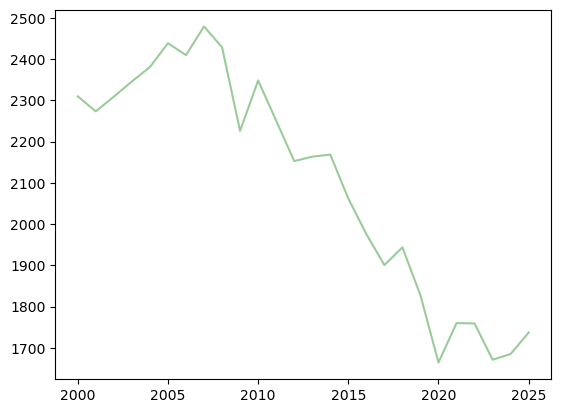

In [8]:
ember.loc[('USA', slice(None), 'Emissions|CO2|Power Industry|Total', slice(None)), 1990:].T.plot(legend=False, color='green', alpha=0.4)

In [2]:
n_steps

2

In [ ]:
range(n_steps)

range(0, 2)

: 